In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nlp-getting-started/sample_submission.csv
/kaggle/input/competitions/nlp-getting-started/train.csv
/kaggle/input/competitions/nlp-getting-started/test.csv
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt


# Keras NLP starter guide here:
https://keras.io/guides/keras_nlp/getting_started/

In this competition, the challenge is to build a machine learning model that predixts which Tweets are about real disasters and which one's aren't. A dataset of 10,000 tweets that were hand classified is available.

### This starter notebook uses the DistillBERT pretrained model from KerasNLP.

BERT stands for Bidirectional Encoder Representations from Transformers. BERT and other Transformer encoder architectures have been wildly successful on a variety of tasks in NLP (natural language processing). They compute vector-space representations of natural language that are suitable for use in deep learning models.

The BERT family of models uses the Transformer encoder architecture to process each token of input text in the full context of all tokens before and after, hence the name: Bidirectional Encoder Representations from Transformers.

BERT models are usually pre-trained on a large corpus of text, then fine-tuned for specific tasks.

DistilBERT model is a distilled form of the BERT model. The size of a BERT model was reduced by 40% via knowledge distillation during the pre-training phase while retaining 97% of its language understanding abilities and being 60% faster.


In this notebook, you will:

Load the Disaster Tweets
Explore the dataset
Preprocess the data
Load a DistilBERT model from Keras NLP
Train your own model, fine-tuning BERT
Generate the submission file

In [2]:
!pip install keras-core --upgrade
!pip install -q keras-nlp --upgrade

import os
os.environ['KERAS_BACKEND']='tensorflow'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 23.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.5 MB/s eta 0:00:00:00:01


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
os.environ["KERAS_BACKEND"] = "jax"   # 或 "tensorflow" / "torch"，必须在 import keras 之前设置

import keras
import keras_hub
import keras_nlp
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("KerasNLP version:", keras_nlp.__version__)

TensorFlow version: 2.20.0
KerasNLP version: 0.32.0


## Load the Disaster Tweets
Lets have a look at the train and test dataset.

They contain:
* id
* keyword: A keyword from that tweet(although this may be blank!)
* location: The location the tweet was sent from(may also be blank)
* text: The text of a tweet
* target: 1 if the tweet is a real disaster or 0 if not

In [4]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('nlp-getting-started')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/nlp-getting-started


In [5]:
df_train = pd.read_csv(path+"/train.csv")
df_test = pd.read_csv(path+"/test.csv")

print('Training Set Shape={}'.format(df_train.shape))
print('Training Set Momory Usage = {:.2f} MB'.format(df_train.memory_usage().sum()/1024**2))
print('Test Set Shape = {}'.format(df_test.shape))
print('Test Set Memory Usage = {:.2f} MB'.format(df_test.memory_usage().sum()/1024**2))

Training Set Shape=(7613, 5)
Training Set Momory Usage = 0.29 MB
Test Set Shape = (3263, 4)
Test Set Memory Usage = 0.10 MB


In [6]:
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [7]:
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, s..."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are..."
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


# Explore the dataset

In [8]:
df_train["length"] = df_train["text"].apply(lambda x :len(x))
df_test["length"] = df_test["text"].apply(lambda x : len(x))

print("Train Length Stat")
print(df_train["length"].describe())
print()
 

print("Test Length Stat")
print(df_test["length"].describe())

Train Length Stat
count    7613.000000
mean      101.037436
std        33.781325
min         7.000000
25%        78.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: length, dtype: float64

Test Length Stat
count    3263.000000
mean      102.108183
std        33.972158
min         5.000000
25%        78.000000
50%       109.000000
75%       134.000000
max       151.000000
Name: length, dtype: float64


If you want to know more information about the data, you can grab useful information here.
Note that all the tweets ate in english.

# Preprocess the data

In [9]:
BATCH_SIZE = 32
NUM_TRAINING_EXAMPLES = df_train.shape[0]
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.2
STEPS_PER_EPOCH = int(NUM_TRAINING_EXAMPLES)*TRAIN_SPLIT // BATCH_SIZE

EPOCH = 2
AUTO = tf.data.experimental.AUTOTUNE

In [10]:
from sklearn.model_selection import train_test_split

X = df_train['text']
y = df_train['target']

X_train, X_val, y_train,y_val = train_test_split(X, y, test_size = VAL_SPLIT, random_state=42)

X_test=df_test['text']

# Load a DistilBERT model from Keras NLP

Text input need to be transformed to numeric token ids and arranged in several Tensors before being input to BERT.

The BertClassifier model can be configured with a preprocessor layer, in which case it will automatically apply preprocessing to raw inputs during fit(), predict(), and evaluate(). This is done by default when creating the model with from_preset().


We will choose DistilBERT model. That learns a distilled(approximate) version of BERT,retaining 97% performence but suing only half the number of parameters.

It has 40% less parameters than bert-uncased, runs 60% faster while preseving over 95% of BERT's performances as  measures on the GLUE language understanding benchmark.

Specificially, it doesnot have token-type embeddings, pooler and retains only half od the layers from Google's BERT.

In [11]:
preset = 'distil_bert_base_en_uncased'
preprocessor = keras_nlp.models.DistilBertPreprocessor.from_preset(preset,
sequence_length = 160,
name='preprocessor_4_tweets')

classifier = keras_nlp.models.DistilBertClassifier.from_preset(preset,
                                                              preprocessor = preprocessor,
                                                              num_classes=2)
classifier.summary()

I0000 00:00:1792172149.281327      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792172149.284962      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Preprocessor: "preprocessor_4_tweets"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

# Train your own model, fine-tuning BERT

In [12]:
classifier.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), #'binary_crossentropy',
    optimizer=keras.optimizers.Adam(1e-5),
    metrics= ["accuracy"]  
)

# Fit
history = classifier.fit(x=X_train,
                         y=y_train,
                         batch_size=BATCH_SIZE,
                         epochs=EPOCH, 
                         validation_data=(X_val, y_val)
                        )

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2


I0000 00:00:1792172200.668020     159 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


191/191 ━━━━━━━━━━━━━━━━━━━━ 151s 593ms/step - accuracy: 0.7747 - loss: 0.4918 - val_accuracy: 0.8424 - val_loss: 0.3923
Epoch 2/2
191/191 ━━━━━━━━━━━━━━━━━━━━ 92s 483ms/step - accuracy: 0.8509 - loss: 0.3695 - val_accuracy: 0.8457 - val_loss: 0.3855


In [13]:
def displayConfusionMatrix(y_true, y_pred,dataset):
    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        np.argmax(y_pred, axis=1),
        display_labels=["Not Disaster", "Disaster"],
        cmap=plt.cm.Blues
    )

    tn,fp,fn,tp = confusion_matrix(y_true, np.argmax(y_pred, axis=1)).ravel()
    f1_score = tp / (tp+((fn+fp)/2))

    disp.ax_.set_title("Confusion Matrix on " + dataset + " Dataset -- F1 Score: " + str(f1_score.round(2)))
    

191/191 ━━━━━━━━━━━━━━━━━━━━ 38s 169ms/step


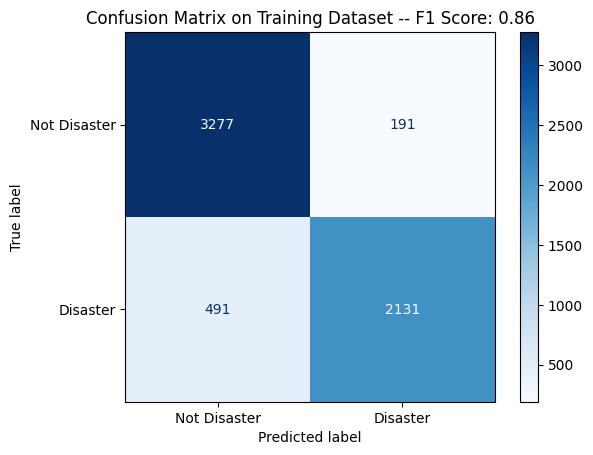

In [14]:
y_pred_train = classifier.predict(X_train)
displayConfusionMatrix(y_train, y_pred_train, "Training")

48/48 ━━━━━━━━━━━━━━━━━━━━ 12s 172ms/step


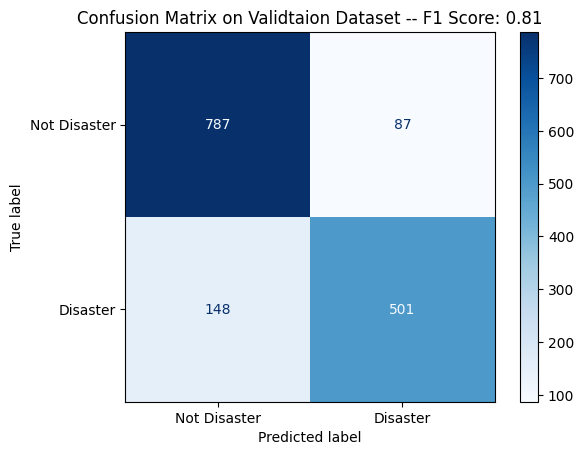

In [15]:
y_pred_val = classifier.predict(X_val)
displayConfusionMatrix(y_val, y_pred_val, "Validtaion")

# Generate the submission file

For each tweets in the test set, we predict if the given tweet is about a real disaster or not. If so, predict a 1. If not, predict a 0.

The submission.csv file uses the following format: id, target

In [23]:
sample_submission = pd.read_csv(path+"/sample_submission.csv")
sample_submission.head()

,id,target
0,0,0
1,2,0
2,3,0
3,9,0
4,11,0


In [24]:
sample_submission["target"] = np.argmax(classifier.predict(X_test), axis=1)

102/102 ━━━━━━━━━━━━━━━━━━━━ 42s 380ms/step


In [25]:
sample_submission.describe()

,id,target
count,3263.000000,3263.000000
mean,5427.152927,0.368679
std,3146.427221,0.482521
min,0.000000,0.000000
25%,2683.000000,0.000000
50%,5500.000000,0.000000
75%,8176.000000,1.000000
max,10875.000000,1.000000


In [29]:
sample_submission.to_csv("submission.csv", index=False)

In [30]:
sample_submission.head()

,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1
